# Machine Sound Classification (Kaggle + Multi-GPU + DagsHub)

This notebook is a full training pipeline from data loading to checkpoint export.

What it does:
- Reads `train_split.csv` and `val_split.csv` only.
- Uses Kaggle dataset folder structure under `/kaggle/input/...`.
- Trains a ResNet-style audio CNN on Mel-spectrograms.
- Automatically uses multiple GPUs with `nn.DataParallel` when available (e.g., T4 x2).
- Optionally logs metrics and artifacts to DagsHub via MLflow.

## 1) Optional package install
This cell uses a safe install strategy for Kaggle to avoid dependency churn in preinstalled packages.

In [1]:
import importlib
import subprocess
import sys

def ensure_mlflow_for_kaggle():
    try:
        import mlflow  # noqa: F401
        print(f"mlflow already available: {mlflow.__version__}")
        return
    except Exception:
        pass

    print("Installing mlflow-skinny with --no-deps to avoid Kaggle package conflicts...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--no-deps",
        "mlflow-skinny==2.12.2",
    ])

    try:
        import mlflow  # noqa: F401
        print(f"Installed mlflow-skinny: {mlflow.__version__}")
    except Exception as e:
        print("mlflow import failed after no-deps install.")
        print("You can continue training without DagsHub logging, or install full mlflow manually.")
        print(f"Reason: {e}")

ensure_mlflow_for_kaggle()

Installing mlflow-skinny with --no-deps to avoid Kaggle package conflicts...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 51.6 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/mlflow/protos/service_pb2.py:11: UserWarning: google.protobuf.service module is deprecated. RPC implementations should provide code generator plugins which generate code specific to the RPC implementation. service.py will be removed in Jan 2025
  from google.protobuf import service as _service


Installed mlflow-skinny: 2.12.2


## 2) Imports

In [2]:
import os
import json
import random
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchaudio
import torchaudio.transforms as T

from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")

## 3) Configuration

In [3]:
@dataclass
class CFG:
    # Fixed Kaggle paths (fast, no auto-discovery).
    dataset_root: str = "/kaggle/input/datasets/karimmyasser/machine-large-dataset"
    data_root: str = "/kaggle/input/datasets/karimmyasser/machine-large-dataset/data"
    train_csv_path: str = "/kaggle/input/datasets/karimmyasser/machine-large-dataset/train_split.csv"
    val_csv_path: str = "/kaggle/input/datasets/karimmyasser/machine-large-dataset/val_split.csv"

    # Audio params
    target_sr: int = 22050
    clip_seconds: float = 5.0
    n_fft: int = 1024
    hop_length: int = 512
    n_mels: int = 128

    # Imbalance handling
    use_weighted_sampler: bool = False
    use_class_weighted_loss: bool = True

    # Training params
    batch_size: int = 64
    val_batch_size: int = 128
    auto_scale_batch_with_gpus: bool = True
    max_train_batch_size: int = 512
    epochs: int = 25
    lr: float = 3e-4
    max_lr: float = 2e-3
    weight_decay: float = 1e-2
    label_smoothing: float = 0.05
    grad_clip: float = 1.0
    mixup_alpha: float = 0.2
    mixup_prob: float = 0.2
    early_stopping_patience: int = 6

    # System params
    seed: int = 42
    num_workers: int = 16
    prefetch_factor: int = 4
    persistent_workers: bool = True
    pin_memory: bool = True
    amp: bool = True
    use_channels_last: bool = True

    # Output
    output_dir: str = "/kaggle/working/machine_sound_run"

    # DagsHub tracking (optional)
    use_dagshub: bool = True
    dagshub_repo_owner: str = "KarimmYasser"
    dagshub_repo_name: str = "machine-sound-classification"
    experiment_name: str = "resnet-machine-sound-training"

cfg = CFG()
Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
print(json.dumps(asdict(cfg), indent=2))

{
  "dataset_root": "/kaggle/input/datasets/karimmyasser/machine-large-dataset",
  "data_root": "/kaggle/input/datasets/karimmyasser/machine-large-dataset/data",
  "train_csv_path": "/kaggle/input/datasets/karimmyasser/machine-large-dataset/train_split.csv",
  "val_csv_path": "/kaggle/input/datasets/karimmyasser/machine-large-dataset/val_split.csv",
  "target_sr": 22050,
  "clip_seconds": 5.0,
  "n_fft": 1024,
  "hop_length": 512,
  "n_mels": 128,
  "use_weighted_sampler": false,
  "use_class_weighted_loss": true,
  "batch_size": 64,
  "val_batch_size": 128,
  "auto_scale_batch_with_gpus": true,
  "max_train_batch_size": 512,
  "epochs": 25,
  "lr": 0.0003,
  "max_lr": 0.002,
  "weight_decay": 0.01,
  "label_smoothing": 0.05,
  "grad_clip": 1.0,
  "mixup_alpha": 0.2,
  "mixup_prob": 0.2,
  "early_stopping_patience": 6,
  "seed": 42,
  "num_workers": 16,
  "prefetch_factor": 4,
  "persistent_workers": true,
  "pin_memory": true,
  "amp": true,
  "use_channels_last": true,
  "output_dir"

## 4) Reproducibility + Device Setup (Auto Multi-GPU)

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(cfg.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()

print(f"Device: {device}")
print(f"GPU count: {n_gpus}")
if n_gpus > 0:
    for i in range(n_gpus):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision("high")
    print("CUDA optimizations enabled: cudnn.benchmark + high matmul precision")

Device: cuda
GPU count: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4
CUDA optimizations enabled: cudnn.benchmark + high matmul precision


## 5) Locate Dataset + Split CSV Files

In [5]:
kaggle_input_root = Path('/kaggle/input')
if not kaggle_input_root.exists():
    raise FileNotFoundError('/kaggle/input not found. Are you running this on Kaggle?')

dataset_root = Path(cfg.dataset_root)
data_root = Path(cfg.data_root)
train_csv_path = Path(cfg.train_csv_path)
val_csv_path = Path(cfg.val_csv_path)

missing = [
    str(p) for p in [dataset_root, data_root, train_csv_path, val_csv_path] if not p.exists()
]
if missing:
    raise FileNotFoundError(
        'The following configured paths do not exist:\n' + '\n'.join(missing)
    )

print(f'Dataset root: {dataset_root}')
print(f'Data root:    {data_root}')
print(f'Train CSV:    {train_csv_path}')
print(f'Val CSV:      {val_csv_path}')

Dataset root: /kaggle/input/datasets/karimmyasser/machine-large-dataset
Data root:    /kaggle/input/datasets/karimmyasser/machine-large-dataset/data
Train CSV:    /kaggle/input/datasets/karimmyasser/machine-large-dataset/train_split.csv
Val CSV:      /kaggle/input/datasets/karimmyasser/machine-large-dataset/val_split.csv


## 6) Load Train/Val Splits and Resolve File Paths

In [6]:
train_df_raw = pd.read_csv(train_csv_path)
val_df_raw = pd.read_csv(val_csv_path)

def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    path_candidates = ["file_path", "filepath", "path", "audio_path"]
    label_candidates = ["label", "target", "class", "y"]

    path_col = next((c for c in path_candidates if c in df.columns), None)
    label_col = next((c for c in label_candidates if c in df.columns), None)

    if path_col is None or label_col is None:
        raise ValueError(f"CSV must include path and label columns. Found: {list(df.columns)}")

    out = df[[path_col, label_col]].copy()
    out.columns = ["file_path", "label"]
    out["label"] = out["label"].astype(int)
    return out

train_df = standardize_columns(train_df_raw)
val_df = standardize_columns(val_df_raw)

# Build fast basename lookup for fallback resolution
all_wavs = list(data_root.rglob("*.wav"))
basename_to_paths = {}
for p in all_wavs:
    basename_to_paths.setdefault(p.name, []).append(p)

def resolve_audio_path(raw_path: str, data_root: Path) -> Path:
    s = str(raw_path).replace('\\', '/').strip()

    p = Path(s)
    if p.exists():
        return p

    # If path already includes /data/... keep only suffix after data
    parts = s.split('/')
    if 'data' in parts:
        idx = parts.index('data')
        candidate = data_root / Path(*parts[idx + 1:])
        if candidate.exists():
            return candidate

    # Common machine anchor fallback
    for machine_name in ['Machine 1', 'Machine 2', 'Machine 3']:
        marker = f'/{machine_name}/'
        if marker in s:
            suffix = s.split(marker, 1)[1]
            candidate = data_root / machine_name / suffix
            if candidate.exists():
                return candidate

    # Last fallback: unique basename match
    base = Path(s).name
    matches = basename_to_paths.get(base, [])
    if len(matches) == 1:
        return matches[0]

    return Path(s)

train_df['audio_path'] = train_df['file_path'].apply(lambda x: str(resolve_audio_path(x, data_root)))
val_df['audio_path'] = val_df['file_path'].apply(lambda x: str(resolve_audio_path(x, data_root)))

train_df = train_df[train_df['audio_path'].apply(lambda p: Path(p).exists())].reset_index(drop=True)
val_df = val_df[val_df['audio_path'].apply(lambda p: Path(p).exists())].reset_index(drop=True)

print(f"Train rows after path resolution: {len(train_df)}")
print(f"Val rows after path resolution:   {len(val_df)}")
print("Train class distribution:")
print(train_df['label'].value_counts().sort_index())

Train rows after path resolution: 39364
Val rows after path resolution:   8436
Train class distribution:
label
0    11340
1     2222
2    11340
3     2268
4    10080
5     2114
Name: count, dtype: int64


## 7) Dataset + Audio Feature Pipeline

In [7]:
class MachineSoundDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        target_sr: int,
        clip_seconds: float,
        n_fft: int,
        hop_length: int,
        n_mels: int,
        train: bool = True,
    ):
        self.df = df.reset_index(drop=True)
        self.target_sr = target_sr
        self.target_len = int(target_sr * clip_seconds)
        self.train = train

        self.mel = T.MelSpectrogram(
            sample_rate=target_sr,
            n_fft=n_fft,
            hop_length=hop_length,
            n_mels=n_mels,
            f_min=0,
            f_max=target_sr // 2,
        )
        self.to_db = T.AmplitudeToDB(stype="power")
        self.freq_mask = T.FrequencyMasking(freq_mask_param=24)
        self.time_mask = T.TimeMasking(time_mask_param=48)

    def __len__(self):
        return len(self.df)

    def _fit_length(self, waveform: torch.Tensor) -> torch.Tensor:
        cur_len = waveform.shape[1]
        if cur_len < self.target_len:
            pad_len = self.target_len - cur_len
            waveform = nn.functional.pad(waveform, (0, pad_len))
        elif cur_len > self.target_len:
            if self.train:
                start = np.random.randint(0, cur_len - self.target_len + 1)
            else:
                start = (cur_len - self.target_len) // 2
            waveform = waveform[:, start:start + self.target_len]
        return waveform

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        path = row['audio_path']
        label = int(row['label'])

        waveform, sr = torchaudio.load(path)

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        if sr != self.target_sr:
            waveform = torchaudio.functional.resample(waveform, sr, self.target_sr)

        waveform = self._fit_length(waveform)

        spec = self.to_db(self.mel(waveform))
        spec = torch.clamp(spec, min=-80.0, max=0.0)

        if self.train:
            if torch.rand(1).item() < 0.8:
                spec = self.freq_mask(spec)
                spec = self.time_mask(spec)

        # Scale from [-80, 0] to [0, 1]
        spec = (spec + 80.0) / 80.0

        return spec, label

## 8) Model (ResNet-style Audio CNN)

In [8]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        self.use_shortcut = stride != 1 or in_channels != out_channels
        if self.use_shortcut:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x, fmap_dict=None, prefix=""):
        out = self.conv1(x)
        out = self.bn1(out)
        out = torch.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        shortcut = self.shortcut(x) if self.use_shortcut else x
        out_add = out + shortcut

        if fmap_dict is not None:
            fmap_dict[f"{prefix}.conv"] = out_add

        out = torch.relu(out_add)
        if fmap_dict is not None:
            fmap_dict[f"{prefix}.relu"] = out

        return out


class AudioCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        self.layer1 = nn.ModuleList([ResidualBlock(64, 64) for i in range(3)])
        self.layer2 = nn.ModuleList(
            [ResidualBlock(64 if i == 0 else 128, 128, stride=2 if i == 0 else 1) for i in range(4)]
        )
        self.layer3 = nn.ModuleList(
            [ResidualBlock(128 if i == 0 else 256, 256, stride=2 if i == 0 else 1) for i in range(6)]
        )
        self.layer4 = nn.ModuleList(
            [ResidualBlock(256 if i == 0 else 512, 512, stride=2 if i == 0 else 1) for i in range(3)]
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x, return_feature_maps=False):
        if not return_feature_maps:
            x = self.conv1(x)
            for block in self.layer1:
                x = block(x)
            for block in self.layer2:
                x = block(x)
            for block in self.layer3:
                x = block(x)
            for block in self.layer4:
                x = block(x)
            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.dropout(x)
            x = self.fc(x)
            return x
        else:
            feature_maps = {}
            x = self.conv1(x)
            feature_maps["conv1"] = x

            for i, block in enumerate(self.layer1):
                x = block(x, feature_maps, prefix=f"layer1.block{i}")
            feature_maps["layer1"] = x

            for i, block in enumerate(self.layer2):
                x = block(x, feature_maps, prefix=f"layer2.block{i}")
            feature_maps["layer2"] = x

            for i, block in enumerate(self.layer3):
                x = block(x, feature_maps, prefix=f"layer3.block{i}")
            feature_maps["layer3"] = x

            for i, block in enumerate(self.layer4):
                x = block(x, feature_maps, prefix=f"layer4.block{i}")
            feature_maps["layer4"] = x

            x = self.avgpool(x)
            x = x.view(x.size(0), -1)
            x = self.dropout(x)
            x = self.fc(x)
            return x, feature_maps

## 9) Training Utilities

In [9]:
def mixup_data(x, y, alpha=0.2):
    if alpha <= 0:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    y_a, y_b = y, y[idx]
    return mixed_x, y_a, y_b, lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


def get_model_state_dict(model: nn.Module):
    return model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()


def train_one_epoch(model, loader, optimizer, scheduler, criterion, scaler, device, cfg):
    model.train()
    running_loss = 0.0
    all_preds, all_targets = [], []

    pbar = tqdm(loader, total=len(loader), desc="Train", leave=False)
    for x, y in pbar:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        if cfg.use_channels_last and device.type == 'cuda':
            x = x.contiguous(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)

        with autocast(enabled=(cfg.amp and device.type == 'cuda')):
            if np.random.rand() < cfg.mixup_prob:
                x_mix, y_a, y_b, lam = mixup_data(x, y, alpha=cfg.mixup_alpha)
                logits = model(x_mix)
                loss = mixup_criterion(criterion, logits, y_a, y_b, lam)
            else:
                logits = model(x)
                loss = criterion(logits, y)

        scaler.scale(loss).backward()

        if cfg.grad_clip is not None and cfg.grad_clip > 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)

        scaler.step(optimizer)
        scaler.update()

        if scheduler is not None:
            scheduler.step()

        running_loss += loss.item()

        preds = logits.detach().argmax(dim=1).cpu().numpy()
        targets = y.detach().cpu().numpy()
        all_preds.extend(preds.tolist())
        all_targets.extend(targets.tolist())

        pbar.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = running_loss / max(len(loader), 1)
    acc = accuracy_score(all_targets, all_preds) if all_targets else 0.0
    f1 = f1_score(all_targets, all_preds, average='macro') if all_targets else 0.0
    return {"loss": avg_loss, "acc": acc, "f1": f1}


@torch.no_grad()
def valid_one_epoch(model, loader, criterion, device, cfg):
    model.eval()
    running_loss = 0.0
    all_preds, all_targets = [], []

    pbar = tqdm(loader, total=len(loader), desc="Valid", leave=False)
    for x, y in pbar:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        if cfg.use_channels_last and device.type == 'cuda':
            x = x.contiguous(memory_format=torch.channels_last)

        with autocast(enabled=(cfg.amp and device.type == 'cuda')):
            logits = model(x)
            loss = criterion(logits, y)

        running_loss += loss.item()
        preds = logits.detach().argmax(dim=1).cpu().numpy()
        targets = y.detach().cpu().numpy()
        all_preds.extend(preds.tolist())
        all_targets.extend(targets.tolist())

    avg_loss = running_loss / max(len(loader), 1)
    acc = accuracy_score(all_targets, all_preds) if all_targets else 0.0
    f1 = f1_score(all_targets, all_preds, average='macro') if all_targets else 0.0
    return {"loss": avg_loss, "acc": acc, "f1": f1}

## 10) Build Dataloaders

In [10]:
num_classes = int(max(train_df['label'].max(), val_df['label'].max()) + 1)
print(f"Num classes: {num_classes}")

label_to_name = {
    0: "Machine 1 - Normal",
    1: "Machine 1 - Abnormal",
    2: "Machine 2 - Normal",
    3: "Machine 2 - Abnormal",
    4: "Machine 3 - Normal",
    5: "Machine 3 - Abnormal",
}

train_ds = MachineSoundDataset(
    train_df,
    target_sr=cfg.target_sr,
    clip_seconds=cfg.clip_seconds,
    n_fft=cfg.n_fft,
    hop_length=cfg.hop_length,
    n_mels=cfg.n_mels,
    train=True,
)

val_ds = MachineSoundDataset(
    val_df,
    target_sr=cfg.target_sr,
    clip_seconds=cfg.clip_seconds,
    n_fft=cfg.n_fft,
    hop_length=cfg.hop_length,
    n_mels=cfg.n_mels,
    train=False,
)

effective_train_bs = cfg.batch_size
if cfg.auto_scale_batch_with_gpus and n_gpus > 1:
    effective_train_bs = min(cfg.batch_size * n_gpus, cfg.max_train_batch_size)

effective_val_bs = max(cfg.val_batch_size, effective_train_bs)

pin_memory = cfg.pin_memory and device.type == 'cuda'
loader_kwargs = {
    'num_workers': cfg.num_workers,
    'pin_memory': pin_memory,
    'persistent_workers': bool(cfg.persistent_workers and cfg.num_workers > 0),
}
if cfg.num_workers > 0:
    loader_kwargs['prefetch_factor'] = cfg.prefetch_factor

# Compute class counts from train split once, then reuse for sampler/loss.
train_label_counts = train_df['label'].value_counts().sort_index()
print('Train class counts:')
print(train_label_counts)

if cfg.use_weighted_sampler:
    class_counts = train_label_counts.reindex(range(num_classes), fill_value=0).values.astype(np.float64)
    class_counts = np.clip(class_counts, a_min=1.0, a_max=None)
    class_sample_weights = 1.0 / class_counts
    sample_weights = train_df['label'].map(lambda y: class_sample_weights[int(y)]).values.astype(np.float64)
    train_sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(sample_weights),
        replacement=True,
    )
    train_shuffle = False
    print('Using WeightedRandomSampler for imbalance handling.')
else:
    train_sampler = None
    train_shuffle = True
    print('Using regular random shuffle (no weighted sampler).')

train_loader = DataLoader(
    train_ds,
    batch_size=effective_train_bs,
    shuffle=train_shuffle,
    sampler=train_sampler,
    drop_last=True,
    **loader_kwargs,
)

val_loader = DataLoader(
    val_ds,
    batch_size=effective_val_bs,
    shuffle=False,
    drop_last=False,
    **loader_kwargs,
)

print(f"Train batch size: {effective_train_bs}")
print(f"Val batch size:   {effective_val_bs}")
print(f"Num workers:      {cfg.num_workers}")
print(f"Train batches:    {len(train_loader)}")
print(f"Val batches:      {len(val_loader)}")

Num classes: 6
Train class counts:
label
0    11340
1     2222
2    11340
3     2268
4    10080
5     2114
Name: count, dtype: int64
Using regular random shuffle (no weighted sampler).
Train batch size: 128
Val batch size:   128
Num workers:      16
Train batches:    307
Val batches:      66


## 11) Initialize Model, Optimizer, Scheduler

In [11]:
model = AudioCNN(num_classes=num_classes)

if n_gpus > 1:
    print(f"Using DataParallel on {n_gpus} GPUs")
    model = nn.DataParallel(model)

model = model.to(device)
if cfg.use_channels_last and device.type == 'cuda':
    model = model.to(memory_format=torch.channels_last)
    print('Using channels_last memory format for model/input tensors.')

if cfg.use_class_weighted_loss:
    counts = train_label_counts.reindex(range(num_classes), fill_value=0).values.astype(np.float64)
    counts = np.clip(counts, a_min=1.0, a_max=None)
    weights = counts.sum() / (num_classes * counts)
    class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=cfg.label_smoothing,
    )
    print(f"Using class-weighted loss: {class_weights.detach().cpu().numpy()}")
else:
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    print('Using unweighted cross-entropy loss.')

optimizer = optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=cfg.max_lr,
    epochs=cfg.epochs,
    steps_per_epoch=max(1, len(train_loader)),
    pct_start=0.1,
)

scaler = GradScaler(enabled=(cfg.amp and device.type == 'cuda'))

print('Model/optimizer/scheduler ready.')

Using DataParallel on 2 GPUs
Using channels_last memory format for model/input tensors.
Using class-weighted loss: [0.57854205 2.9525952  0.57854205 2.8927102  0.6508598  3.1034374 ]
Model/optimizer/scheduler ready.


## 12) Optional DagsHub + MLflow Tracking
Add a Kaggle secret named `DAGSHUB_TOKEN` before running this cell.
If unavailable, training still runs locally without remote logging.

In [12]:
mlflow = None
dagshub_enabled = False

if cfg.use_dagshub:
    try:
        from kaggle_secrets import UserSecretsClient
        import mlflow

        secrets = UserSecretsClient()
        token = secrets.get_secret('DAGSHUB_TOKEN')

        try:
            username = secrets.get_secret('DAGSHUB_USERNAME')
        except Exception:
            username = cfg.dagshub_repo_owner

        if not token:
            raise ValueError('DAGSHUB_TOKEN is empty.')

        tracking_uri = f"https://dagshub.com/{cfg.dagshub_repo_owner}/{cfg.dagshub_repo_name}.mlflow"
        os.environ['MLFLOW_TRACKING_URI'] = tracking_uri
        os.environ['MLFLOW_TRACKING_USERNAME'] = username
        os.environ['MLFLOW_TRACKING_PASSWORD'] = token

        mlflow.set_tracking_uri(tracking_uri)
        mlflow.set_experiment(cfg.experiment_name)

        dagshub_enabled = True
        print(f'DagsHub tracking enabled. URI: {tracking_uri}')
    except Exception as e:
        dagshub_enabled = False
        print(f'DagsHub disabled: {e}')
else:
    print('DagsHub disabled by config.')

DagsHub tracking enabled. URI: https://dagshub.com/KarimmYasser/machine-sound-classification.mlflow


## 13) Train + Validate + Save Best Checkpoint

In [13]:
history = []
best_f1 = -1.0
patience_counter = 0

best_ckpt_path = Path(cfg.output_dir) / 'best_model.pth'
history_path = Path(cfg.output_dir) / 'history.csv'
config_path = Path(cfg.output_dir) / 'config.json'

with open(config_path, 'w') as f:
    json.dump(asdict(cfg), f, indent=2)

run_ctx = mlflow.start_run(run_name='kaggle-train') if (dagshub_enabled and mlflow is not None) else nullcontext()

with run_ctx:
    if dagshub_enabled and mlflow is not None:
        mlflow.log_params(asdict(cfg))
        mlflow.log_param('num_gpus', n_gpus)

    for epoch in range(1, cfg.epochs + 1):
        if device.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()

        train_metrics = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, scaler, device, cfg)
        val_metrics = valid_one_epoch(model, val_loader, criterion, device, cfg)

        peak_mem_gb = 0.0
        if device.type == 'cuda':
            peak_mem_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)

        row = {
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'train_acc': train_metrics['acc'],
            'train_f1': train_metrics['f1'],
            'val_loss': val_metrics['loss'],
            'val_acc': val_metrics['acc'],
            'val_f1': val_metrics['f1'],
            'lr': optimizer.param_groups[0]['lr'],
            'peak_gpu_mem_gb': peak_mem_gb,
        }
        history.append(row)

        print(
            f"Epoch {epoch:02d}/{cfg.epochs} | "
            f"train_loss={row['train_loss']:.4f}, train_acc={row['train_acc']:.4f}, train_f1={row['train_f1']:.4f} | "
            f"val_loss={row['val_loss']:.4f}, val_acc={row['val_acc']:.4f}, val_f1={row['val_f1']:.4f} | "
            f"peak_gpu_mem={row['peak_gpu_mem_gb']:.2f} GB"
        )

        if dagshub_enabled and mlflow is not None:
            mlflow.log_metrics({
                'train_loss': row['train_loss'],
                'train_acc': row['train_acc'],
                'train_f1': row['train_f1'],
                'val_loss': row['val_loss'],
                'val_acc': row['val_acc'],
                'val_f1': row['val_f1'],
                'lr': row['lr'],
                'peak_gpu_mem_gb': row['peak_gpu_mem_gb'],
            }, step=epoch)

        if row['val_f1'] > best_f1:
            best_f1 = row['val_f1']
            patience_counter = 0

            checkpoint = {
                'epoch': epoch,
                'model_state_dict': get_model_state_dict(model),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_val_f1': best_f1,
                'num_classes': num_classes,
                'label_to_name': label_to_name,
                'cfg': asdict(cfg),
            }
            torch.save(checkpoint, best_ckpt_path)
            print(f'  Saved new best checkpoint -> {best_ckpt_path}')

            if dagshub_enabled and mlflow is not None:
                mlflow.log_artifact(str(best_ckpt_path))
        else:
            patience_counter += 1

        if patience_counter >= cfg.early_stopping_patience:
            print('Early stopping triggered.')
            break

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    if dagshub_enabled and mlflow is not None:
        mlflow.log_artifact(str(history_path))
        mlflow.log_artifact(str(config_path))

print(f'Best val F1: {best_f1:.4f}')
print(f'History file: {history_path}')

Train:   0%|          | 0/307 [00:00<?, ?it/s]

Valid:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 01/25 | train_loss=0.8198, train_acc=0.7605, train_f1=0.6907 | val_loss=0.7003, val_acc=0.9471, val_f1=0.8970 | peak_gpu_mem=1.29 GB
  Saved new best checkpoint -> /kaggle/working/machine_sound_run/best_model.pth


Train:   0%|          | 0/307 [00:00<?, ?it/s]

Valid:   0%|          | 0/66 [00:00<?, ?it/s]

...

Valid:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 19/25 | train_loss=0.4356, train_acc=0.9216, train_f1=0.9118 | val_loss=0.5515, val_acc=0.9947, val_f1=0.9909 | peak_gpu_mem=0.91 GB


Train:   0%|          | 0/307 [00:00<?, ?it/s]

Valid:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 20/25 | train_loss=0.4415, train_acc=0.9200, train_f1=0.9105 | val_loss=0.5514, val_acc=0.9957, val_f1=0.9928 | peak_gpu_mem=0.91 GB
Early stopping triggered.
Best val F1: 0.9937
History file: /kaggle/working/machine_sound_run/history.csv


## 14) Plot Learning Curves

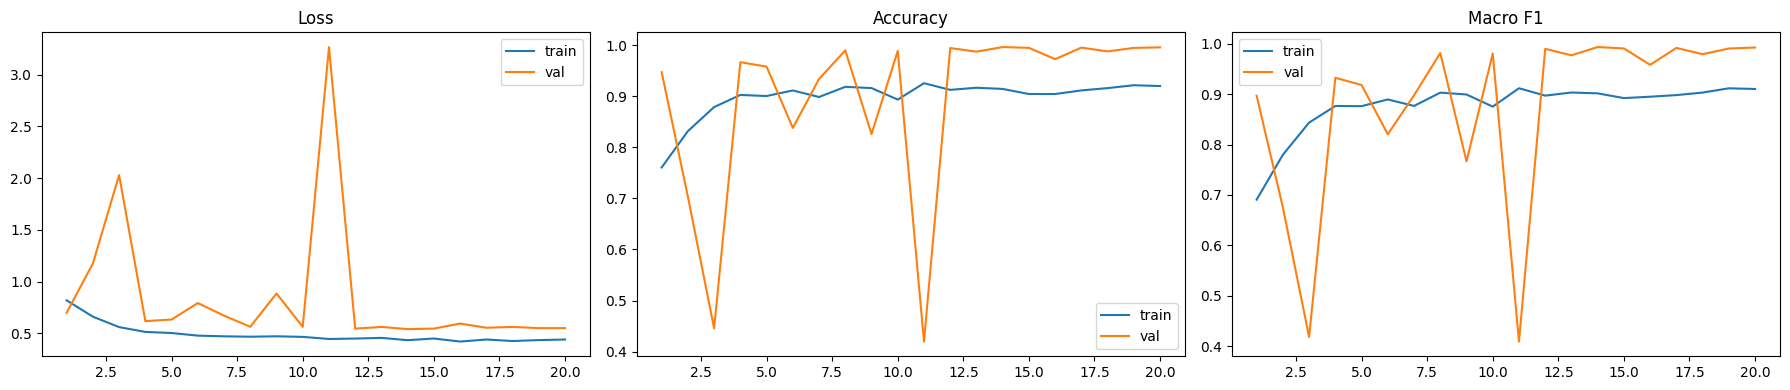

,epoch,train_loss,train_acc,train_f1,val_loss,val_acc,val_f1,lr,peak_gpu_mem_gb
15,16,0.421639,0.904392,0.895110,0.595359,0.972617,0.958455,0.000691,0.908322
16,17,0.441224,0.911416,0.898312,0.555206,0.995258,0.991971,0.000561,0.908322
17,18,0.426759,0.915946,0.903310,0.563115,0.987790,0.979576,0.000440,0.908322
18,19,0.435599,0.921595,0.911790,0.551509,0.994666,0.990890,0.000331,0.908322
19,20,0.441537,0.919966,0.910453,0.551362,0.995733,0.992778,0.000234,0.908322


In [14]:
history_df = pd.read_csv(Path(cfg.output_dir) / 'history.csv')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(history_df['epoch'], history_df['train_loss'], label='train')
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].legend()

axes[1].plot(history_df['epoch'], history_df['train_acc'], label='train')
axes[1].plot(history_df['epoch'], history_df['val_acc'], label='val')
axes[1].set_title('Accuracy')
axes[1].legend()

axes[2].plot(history_df['epoch'], history_df['train_f1'], label='train')
axes[2].plot(history_df['epoch'], history_df['val_f1'], label='val')
axes[2].set_title('Macro F1')
axes[2].legend()

plt.tight_layout()
plt.show()

history_df.tail()

## 15) Inference Sanity Check on One Validation Sample

True label: 2 (Machine 2 - Normal)
Top predictions:
  class=2 (Machine 2 - Normal), confidence=0.8558
  class=3 (Machine 2 - Abnormal), confidence=0.0466
  class=5 (Machine 3 - Abnormal), confidence=0.0405


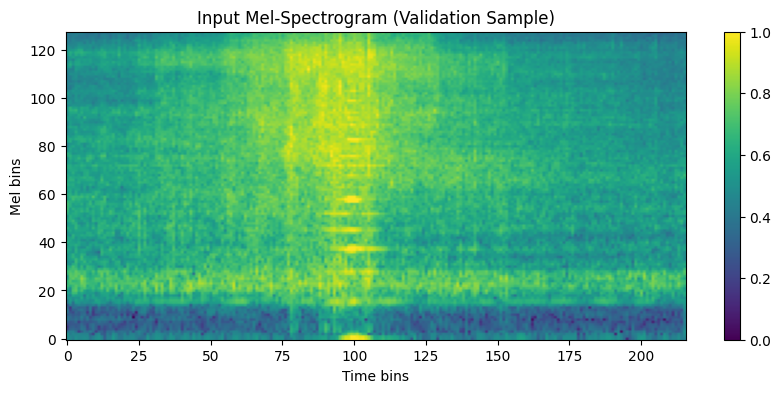

In [15]:
best_ckpt_path = Path(cfg.output_dir) / 'best_model.pth'
checkpoint = torch.load(best_ckpt_path, map_location=device)

inference_model = AudioCNN(num_classes=checkpoint['num_classes']).to(device)
inference_model.load_state_dict(checkpoint['model_state_dict'])
inference_model.eval()

sample_idx = np.random.randint(0, len(val_ds))
sample_spec, sample_label = val_ds[sample_idx]
sample_input = sample_spec.unsqueeze(0).to(device)

with torch.no_grad():
    logits = inference_model(sample_input)
    probs = torch.softmax(logits, dim=1)[0]

top_k = min(3, checkpoint['num_classes'])
top_probs, top_ids = torch.topk(probs, k=top_k)

true_name = label_to_name.get(int(sample_label), str(sample_label))
print(f'True label: {sample_label} ({true_name})')
print('Top predictions:')
for p, i in zip(top_probs.tolist(), top_ids.tolist()):
    name = label_to_name.get(int(i), str(i))
    print(f'  class={i} ({name}), confidence={p:.4f}')

plt.figure(figsize=(10, 4))
plt.imshow(sample_spec.squeeze(0).numpy(), origin='lower', aspect='auto')
plt.title('Input Mel-Spectrogram (Validation Sample)')
plt.xlabel('Time bins')
plt.ylabel('Mel bins')
plt.colorbar()
plt.show()

## 16) Export Artifacts for Download / Reuse

In [16]:
output_dir = Path(cfg.output_dir)
archive_path = Path('/kaggle/working/machine_sound_artifacts.zip')

if archive_path.exists():
    archive_path.unlink()

import shutil
shutil.make_archive('/kaggle/working/machine_sound_artifacts', 'zip', root_dir=output_dir)

print(f'Artifacts zip created: {archive_path}')
print('Files in output directory:')
for p in sorted(output_dir.glob('*')):
    print(' -', p)

Artifacts zip created: /kaggle/working/machine_sound_artifacts.zip
Files in output directory:
 - /kaggle/working/machine_sound_run/best_model.pth
 - /kaggle/working/machine_sound_run/config.json
 - /kaggle/working/machine_sound_run/history.csv


## Notes
- This notebook trains only on `train_split.csv` and validates on `val_split.csv`.
- You can build a separate notebook for test-time evaluation using `test_split.csv` and the saved `best_model.pth`.
- For DagsHub logging on Kaggle, set a secret named `DAGSHUB_TOKEN`.

## Final Accuracy Test (Best Checkpoint on Test Set)
This runs a post-training evaluation on `test_split.csv` using the saved best checkpoint and prints final test accuracy/F1.

In [17]:
test_csv_path = Path(str(cfg.train_csv_path).replace('train_split.csv', 'test_split.csv'))
if not test_csv_path.exists():
    raise FileNotFoundError(
        f'test_split.csv not found at expected location: {test_csv_path}'
    )

test_df_raw = pd.read_csv(test_csv_path)
test_df = standardize_columns(test_df_raw)
test_df['audio_path'] = test_df['file_path'].apply(lambda x: str(resolve_audio_path(x, data_root)))
test_df = test_df[test_df['audio_path'].apply(lambda p: Path(p).exists())].reset_index(drop=True)

print(f'Test rows after path resolution: {len(test_df)}')
if len(test_df) == 0:
    raise ValueError('No resolved test files found after path resolution.')

test_ds = MachineSoundDataset(
    test_df,
    target_sr=cfg.target_sr,
    clip_seconds=cfg.clip_seconds,
    n_fft=cfg.n_fft,
    hop_length=cfg.hop_length,
    n_mels=cfg.n_mels,
    train=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=effective_val_bs,
    shuffle=False,
    drop_last=False,
    **loader_kwargs,
)

best_ckpt_path = Path(cfg.output_dir) / 'best_model.pth'
if not best_ckpt_path.exists():
    raise FileNotFoundError(f'Best checkpoint not found: {best_ckpt_path}')

best_checkpoint = torch.load(best_ckpt_path, map_location=device)

final_eval_model = AudioCNN(num_classes=best_checkpoint['num_classes']).to(device)
if cfg.use_channels_last and device.type == 'cuda':
    final_eval_model = final_eval_model.to(memory_format=torch.channels_last)

final_eval_model.load_state_dict(best_checkpoint['model_state_dict'])
final_eval_model.eval()

final_test_metrics = valid_one_epoch(final_eval_model, test_loader, criterion, device, cfg)

print('Final test metrics from best checkpoint:')
print(f"  Accuracy: {final_test_metrics['acc']:.4f}")
print(f"  Macro F1: {final_test_metrics['f1']:.4f}")
print(f"  Loss:     {final_test_metrics['loss']:.4f}")

# Optional pass/fail test: set a target threshold to enforce a minimum final test accuracy.
target_final_test_acc = None  # e.g. 0.85
if target_final_test_acc is not None:
    passed = final_test_metrics['acc'] >= target_final_test_acc
    print(f"  Target test accuracy: {target_final_test_acc:.4f}")
    print(f"  Accuracy test: {'PASS' if passed else 'FAIL'}")
    if not passed:
        raise AssertionError(
            f"Final test accuracy {final_test_metrics['acc']:.4f} is below target {target_final_test_acc:.4f}"
        )

Test rows after path resolution: 8436


Valid:   0%|          | 0/66 [00:02<?, ?it/s]

Final test metrics from best checkpoint:
  Accuracy: 0.9738
  Macro F1: 0.9568
  Loss:     0.6035


## Detailed Test Metrics (Per-Class Precision/Recall, Confusion Matrix, mAP)
This section computes detailed class-wise metrics from test predictions using the best checkpoint.

Test Detailed Eval:   0%|          | 0/66 [00:00<?, ?it/s]

Per-class test metrics:


,class_id,class_name,precision,recall,f1,support
0,0,Machine 1 - Normal,0.987715,0.992593,0.990148,2430
1,1,Machine 1 - Abnormal,0.961123,0.932914,0.946809,477
2,2,Machine 2 - Normal,0.987075,0.942798,0.964429,2430
3,3,Machine 2 - Abnormal,0.763819,0.938272,0.842105,486
4,4,Machine 3 - Normal,0.999075,1.000000,0.999537,2160
5,5,Machine 3 - Abnormal,1.000000,0.995585,0.997788,453


Confusion matrix (all class pairs):


,pred_Machine 1 - Normal,pred_Machine 1 - Abnormal,pred_Machine 2 - Normal,pred_Machine 2 - Abnormal,pred_Machine 3 - Normal,pred_Machine 3 - Abnormal
true_Machine 1 - Normal,2412,18,0,0,0,0
true_Machine 1 - Abnormal,30,445,0,2,0,0
true_Machine 2 - Normal,0,0,2291,139,0,0
true_Machine 2 - Abnormal,0,0,30,456,0,0
true_Machine 3 - Normal,0,0,0,0,2160,0
true_Machine 3 - Abnormal,0,0,0,0,2,451


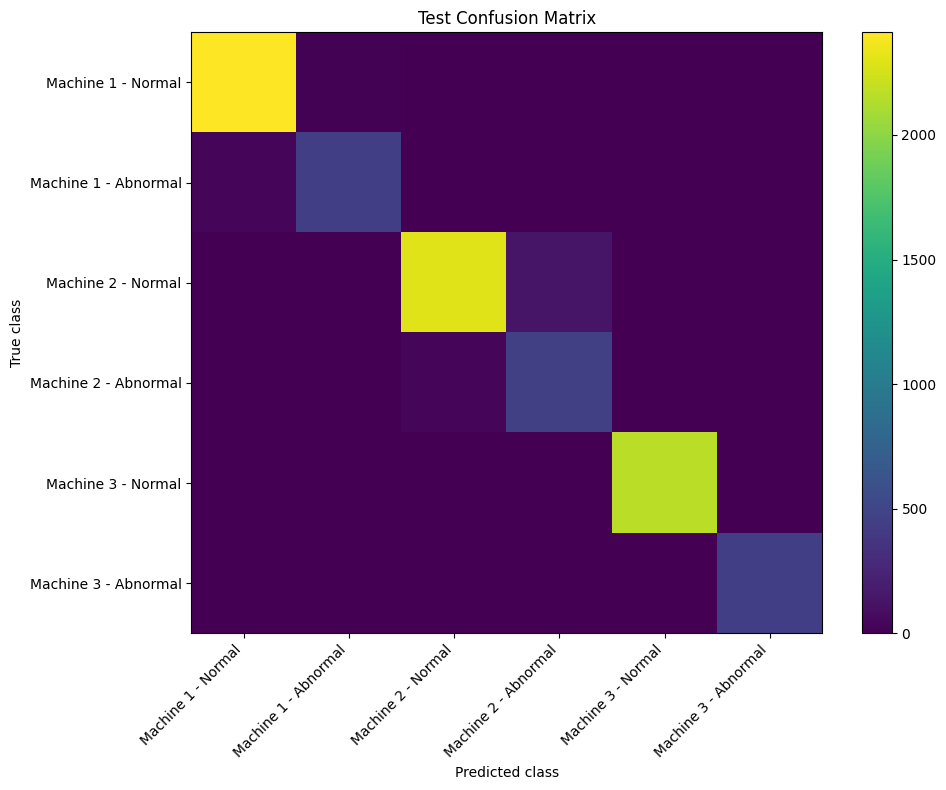

Pairwise confusions (sorted):


,true_class_id,true_class_name,pred_class_id,pred_class_name,count
0,2,Machine 2 - Normal,3,Machine 2 - Abnormal,139
1,1,Machine 1 - Abnormal,0,Machine 1 - Normal,30
2,3,Machine 2 - Abnormal,2,Machine 2 - Normal,30
3,0,Machine 1 - Normal,1,Machine 1 - Abnormal,18
4,5,Machine 3 - Abnormal,4,Machine 3 - Normal,2
5,1,Machine 1 - Abnormal,3,Machine 2 - Abnormal,2
6,0,Machine 1 - Normal,5,Machine 3 - Abnormal,0
7,0,Machine 1 - Normal,4,Machine 3 - Normal,0
8,1,Machine 1 - Abnormal,4,Machine 3 - Normal,0
9,1,Machine 1 - Abnormal,2,Machine 2 - Normal,0


Per-class Average Precision:


,class_id,class_name,average_precision
0,0,Machine 1 - Normal,0.989089
1,1,Machine 1 - Abnormal,0.970890
2,2,Machine 2 - Normal,0.992782
3,3,Machine 2 - Abnormal,0.945503
4,4,Machine 3 - Normal,1.000000
5,5,Machine 3 - Abnormal,1.000000


mAP (macro over classes): 0.983044


In [18]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, average_precision_score

# Collect labels, predicted classes, and class probabilities on the full test set.
all_test_targets = []
all_test_preds = []
all_test_probs = []

final_eval_model.eval()
with torch.no_grad():
    for x, y in tqdm(test_loader, total=len(test_loader), desc='Test Detailed Eval', leave=False):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        if cfg.use_channels_last and device.type == 'cuda':
            x = x.contiguous(memory_format=torch.channels_last)

        with autocast(enabled=(cfg.amp and device.type == 'cuda')):
            logits = final_eval_model(x)
            probs = torch.softmax(logits, dim=1)

        preds = probs.argmax(dim=1)

        all_test_targets.extend(y.detach().cpu().numpy().tolist())
        all_test_preds.extend(preds.detach().cpu().numpy().tolist())
        all_test_probs.append(probs.detach().cpu().numpy())

all_test_targets = np.array(all_test_targets, dtype=np.int64)
all_test_preds = np.array(all_test_preds, dtype=np.int64)
all_test_probs = np.concatenate(all_test_probs, axis=0)

# Per-class precision and recall.
labels = list(range(num_classes))
precision, recall, f1, support = precision_recall_fscore_support(
    all_test_targets,
    all_test_preds,
    labels=labels,
    average=None,
    zero_division=0,
)

metrics_df = pd.DataFrame({
    'class_id': labels,
    'class_name': [label_to_name.get(i, str(i)) for i in labels],
    'precision': precision,
    'recall': recall,
    'f1': f1,
    'support': support,
})

print('Per-class test metrics:')
display(metrics_df)

# Full confusion matrix: rows=true classes, cols=predicted classes.
cm = confusion_matrix(all_test_targets, all_test_preds, labels=labels)
cm_df = pd.DataFrame(
    cm,
    index=[f"true_{label_to_name.get(i, i)}" for i in labels],
    columns=[f"pred_{label_to_name.get(i, i)}" for i in labels],
)

print('Confusion matrix (all class pairs):')
display(cm_df)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', aspect='auto')
plt.title('Test Confusion Matrix')
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.xticks(ticks=np.arange(num_classes), labels=[label_to_name.get(i, i) for i in labels], rotation=45, ha='right')
plt.yticks(ticks=np.arange(num_classes), labels=[label_to_name.get(i, i) for i in labels])
plt.colorbar()
plt.tight_layout()
plt.show()

# Pairwise confusion counts for every ordered pair (true_i -> pred_j, i != j).
pairwise_rows = []
for i in labels:
    for j in labels:
        if i == j:
            continue
        pairwise_rows.append({
            'true_class_id': i,
            'true_class_name': label_to_name.get(i, str(i)),
            'pred_class_id': j,
            'pred_class_name': label_to_name.get(j, str(j)),
            'count': int(cm[i, j]),
        })
pairwise_confusions_df = pd.DataFrame(pairwise_rows).sort_values('count', ascending=False).reset_index(drop=True)

print('Pairwise confusions (sorted):')
display(pairwise_confusions_df)

# Mean Average Precision (mAP): one-vs-rest AP averaged across classes.
one_hot_targets = np.eye(num_classes, dtype=np.int64)[all_test_targets]
per_class_ap = []
for i in labels:
    ap_i = average_precision_score(one_hot_targets[:, i], all_test_probs[:, i])
    per_class_ap.append(ap_i)

map_score = float(np.mean(per_class_ap))
ap_df = pd.DataFrame({
    'class_id': labels,
    'class_name': [label_to_name.get(i, str(i)) for i in labels],
    'average_precision': per_class_ap,
})

print('Per-class Average Precision:')
display(ap_df)
print(f'mAP (macro over classes): {map_score:.6f}')